In [5]:
import os
import psycopg2
import pandas as pd
from dotenv import load_dotenv

# Cargar variables desde el archivo .env en la raíz del proyecto
load_dotenv(dotenv_path="../.env")

conn = psycopg2.connect(
    host=os.getenv("POSTGRES_HOST", "localhost"),
    port=os.getenv("POSTGRES_PORT", "5433"),
    dbname=os.getenv("POSTGRES_DB", "dw_turismo_ods8_v2"),
    user=os.getenv("POSTGRES_USER", "etl_user"),
    password=os.getenv("POSTGRES_PASSWORD", "etl_password")
)

# Listar todas las tablas disponibles en la base de datos
query_tablas = """
SELECT table_name 
FROM information_schema.tables 
WHERE table_schema = 'public'
ORDER BY table_name;
"""
tablas = pd.read_sql(query_tablas, conn)["table_name"].tolist()
print("Tablas encontradas en dw_turismo_ods8_v2:", tablas)

for tabla in tablas:
    df_cols = pd.read_sql(
        f"SELECT column_name, data_type FROM information_schema.columns WHERE table_name = '{tabla}' ORDER BY ordinal_position;",
        conn
    )
    total = pd.read_sql(f"SELECT COUNT(*) AS n FROM {tabla};", conn)["n"][0]
    cols_info = [f"{r['column_name']} ({r['data_type']})" for _, r in df_cols.iterrows()]
    print(f"- {tabla} ({total:,} registros): {cols_info}")

conn.close()

C:\Users\Usuario\AppData\Local\Temp\ipykernel_19384\3490822943.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  tablas = pd.read_sql(query_tablas, conn)["table_name"].tolist()


Tablas encontradas en dw_turismo_ods8_v2: ['dim_categoria', 'dim_ubicacion', 'fact_turismo_anual', 'streaming_invalid_events', 'streaming_metrics']
- dim_categoria (5 registros): ['id_categoria (integer)', 'categoria (character varying)', 'sub_categoria (character varying)']
- dim_ubicacion (6 registros): ['codigo_municipio (integer)', 'municipio (character varying)', 'codigo_departamento (integer)', 'departamento (character varying)']
- fact_turismo_anual (15 registros): ['id_fact (integer)', 'codigo_rnt (integer)', 'codigo_municipio (integer)', 'id_categoria (integer)', 'anio (integer)', 'numero_de_habitaciones (integer)', 'numero_de_camas (integer)', 'numero_de_empleados (integer)']
- streaming_invalid_events (16 registros): ['id_error (integer)', 'raw_payload (text)', 'motivo_rechazo (character varying)', 'fecha_rechazo (timestamp without time zone)']
- streaming_metrics (6 registros): ['departamento (character varying)', 'total_pst_procesados (integer)', 'total_empleados_stream (i

C:\Users\Usuario\AppData\Local\Temp\ipykernel_19384\3490822943.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_cols = pd.read_sql(
C:\Users\Usuario\AppData\Local\Temp\ipykernel_19384\3490822943.py:32: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  total = pd.read_sql(f"SELECT COUNT(*) AS n FROM {tabla};", conn)["n"][0]
C:\Users\Usuario\AppData\Local\Temp\ipykernel_19384\3490822943.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_cols = pd.read_sql(
C:\Users\Usuario\AppData\Local\Temp\ipykernel_19384\3490822943

In [6]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

conn = psycopg2.connect(
    host=os.getenv("POSTGRES_HOST", "localhost"),
    port=os.getenv("POSTGRES_PORT", "5433"),
    dbname=os.getenv("POSTGRES_DB", "dw_turismo_ods8_v2"),
    user=os.getenv("POSTGRES_USER", "etl_user"),
    password=os.getenv("POSTGRES_PASSWORD", "etl_password")
)

query_dw = """
SELECT 
    f.id_fact,
    f.codigo_rnt,
    f.anio,
    u.codigo_departamento,
    u.departamento,
    u.codigo_municipio,
    u.municipio,
    c.categoria,
    c.sub_categoria,
    f.numero_de_habitaciones,
    f.numero_de_camas,
    f.numero_de_empleados
FROM fact_turismo_anual f
LEFT JOIN dim_ubicacion u ON f.codigo_municipio = u.codigo_municipio
LEFT JOIN dim_categoria c ON f.id_categoria = c.id_categoria;
"""

df_dw = pd.read_sql(query_dw, conn)
df_stream = pd.read_sql("SELECT * FROM streaming_metrics;", conn)
df_invalid = pd.read_sql("SELECT * FROM streaming_invalid_events;", conn)
conn.close()

print("=== 1. VALORES NULOS EN EL DATA WAREHOUSE ===")
print(df_dw.isnull().sum())

print("\n=== 2. ESTADÍSTICAS DESCRIPTIVAS (MÉTRICAS NUMÉRICAS) ===")
display(df_dw[["anio", "numero_de_habitaciones", "numero_de_camas", "numero_de_empleados"]].describe().T)

print("\n=== 3. MUESTRA CONSOLIDADA DEL DATA WAREHOUSE ===")
display(df_dw.head(10))

print("\n=== 4. AUDITORÍA DE EVENTOS INVÁLIDOS EN STREAMING (MOTIVOS DE RECHAZO) ===")
display(df_invalid["motivo_rechazo"].value_counts().to_frame(name="cantidad_rechazos"))

=== 1. VALORES NULOS EN EL DATA WAREHOUSE ===
id_fact                   0
codigo_rnt                0
anio                      0
codigo_departamento       0
departamento              0
codigo_municipio          0
municipio                 0
categoria                 0
sub_categoria             0
numero_de_habitaciones    0
numero_de_camas           0
numero_de_empleados       0
dtype: int64

=== 2. ESTADÍSTICAS DESCRIPTIVAS (MÉTRICAS NUMÉRICAS) ===


,count,mean,std,min,25%,50%,75%,max
anio,15.0,2025.200000,0.414039,2025.0,2025.0,2025.0,2025.0,2026.0
numero_de_habitaciones,15.0,55.133333,47.995337,0.0,14.5,45.0,90.0,150.0
numero_de_camas,15.0,107.266667,95.243647,0.0,29.0,80.0,157.5,310.0
numero_de_empleados,15.0,38.600000,32.277369,4.0,10.5,32.0,58.0,110.0



=== 3. MUESTRA CONSOLIDADA DEL DATA WAREHOUSE ===


,id_fact,codigo_rnt,anio,codigo_departamento,departamento,codigo_municipio,municipio,categoria,sub_categoria,numero_de_habitaciones,numero_de_camas,numero_de_empleados
0,1,10245,2025,76,VALLE DEL CAUCA,76001,CALI,ESTABLECIMIENTOS DE ALOJAMIENTO Y HOSPEDAJE,HOTEL,45,80,28
1,2,10890,2025,76,VALLE DEL CAUCA,76001,CALI,AGENCIAS DE VIAJES,AGENCIA DE VIAJES Y DE TURISMO,0,0,12
2,3,20411,2025,13,BOLIVAR,13001,CARTAGENA,ESTABLECIMIENTOS DE ALOJAMIENTO Y HOSPEDAJE,HOTEL,120,240,85
3,4,20988,2025,13,BOLIVAR,13001,CARTAGENA,VIVIENDAS TURISTICAS,APARTAMENTO TURISTICO,15,30,6
4,5,30112,2025,11,"BOGOTA, D.C.",11001,"BOGOTA, D.C.",ESTABLECIMIENTOS DE ALOJAMIENTO Y HOSPEDAJE,HOTEL,95,160,64
5,6,30544,2025,11,"BOGOTA, D.C.",11001,"BOGOTA, D.C.",ESTABLECIMIENTOS DE GASTRONOMIA Y SIMILARES,RESTAURANTE TURISTICO,0,0,32
6,7,40210,2025,5,ANTIOQUIA,5001,MEDELLIN,ESTABLECIMIENTOS DE ALOJAMIENTO Y HOSPEDAJE,HOTEL,70,130,41
7,8,40789,2025,5,ANTIOQUIA,5001,MEDELLIN,ESTABLECIMIENTOS DE ALOJAMIENTO Y HOSPEDAJE,HOSTAL,18,42,9
8,9,50123,2025,47,MAGDALENA,47001,SANTA MARTA,ESTABLECIMIENTOS DE ALOJAMIENTO Y HOSPEDAJE,HOTEL,110,225,73
9,10,50677,2025,47,MAGDALENA,47001,SANTA MARTA,VIVIENDAS TURISTICAS,APARTAMENTO TURISTICO,10,22,4



=== 4. AUDITORÍA DE EVENTOS INVÁLIDOS EN STREAMING (MOTIVOS DE RECHAZO) ===


,cantidad_rechazos
motivo_rechazo,
Error de formato JSON: Expecting property name enclosed in double quotes: line 1 column 2 (char 1),4
Campo obligatorio faltante o nulo: 'event_id',4
"Tipo de dato inválido en 'numero_de_empleados': se esperaba int, llegó str",4
Métricas numéricas negativas no permitidas por el contrato.,4


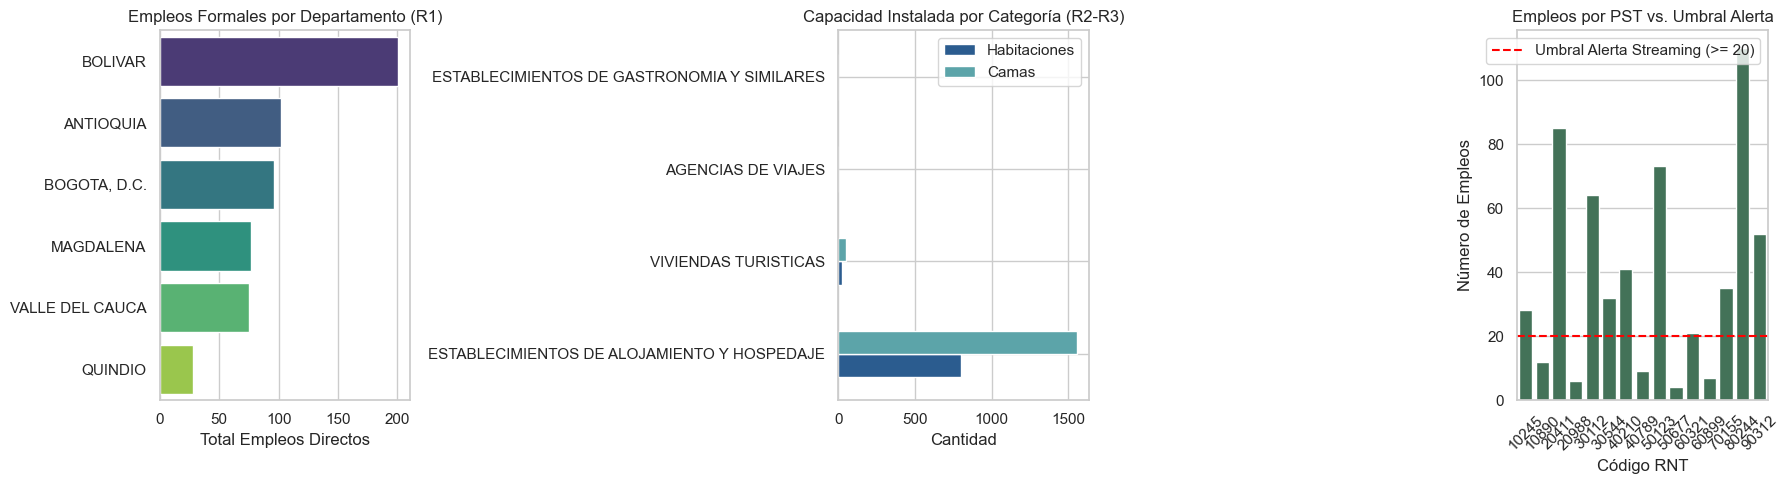

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfica 1: Empleos formales por departamento (R1)
depto_emp = df_dw.groupby("departamento")["numero_de_empleados"].sum().sort_values(ascending=False)
sns.barplot(x=depto_emp.values, y=depto_emp.index, ax=axes[0], palette="viridis", hue=depto_emp.index, legend=False)
axes[0].set_title("Empleos Formales por Departamento (R1)")
axes[0].set_xlabel("Total Empleos Directos")
axes[0].set_ylabel("")

# Gráfica 2: Capacidad instalada por categoría comercial (R2 - R3)
cat_cap = df_dw.groupby("categoria")[["numero_de_habitaciones", "numero_de_camas"]].sum().sort_values("numero_de_camas", ascending=False)
cat_cap.plot(kind="barh", ax=axes[1], color=["#2b5c8f", "#5ca4a9"])
axes[1].set_title("Capacidad Instalada por Categoría (R2-R3)")
axes[1].set_xlabel("Cantidad")
axes[1].set_ylabel("")
axes[1].legend(["Habitaciones", "Camas"])

# Gráfica 3: Empleos por establecimiento vs. Umbral de Alto Impacto (>= 20)
sns.barplot(data=df_dw, x="codigo_rnt", y="numero_de_empleados", ax=axes[2], color="#3b7a57")
axes[2].axhline(20, color="red", linestyle="--", linewidth=1.5, label="Umbral Alerta Streaming (>= 20)")
axes[2].set_title("Empleos por PST vs. Umbral Alerta")
axes[2].set_xlabel("Código RNT")
axes[2].set_ylabel("Número de Empleos")
axes[2].tick_params(axis="x", rotation=45)
axes[2].legend()

plt.tight_layout()
plt.show()

## Conclusiones del EDA y Reglas de Calidad

El análisis exploratorio permitió definir las reglas de limpieza (Python), calidad (Great Expectations) y contrato de eventos (Kafka):

* **Ceros válidos en capacidad física:** Categorías como *Agencias de Viajes* y *Gastronomía* registran `0` habitaciones y `0` camas[cite: 6]. Por ello, las reglas aceptan valores `>= 0` (rechazando únicamente números negativos).
* **Llaves geográficas y categóricas:** Los códigos de departamento, municipio (`codigo_municipio`) y categoría (`id_categoria`) se estandarizaron como enteros no nulos para garantizar el cruce sin pérdidas en el modelo estrella.
* **Umbral de alerta en tiempo real:** Al observar que varios prestadores superan los **20 empleados directos**[cite: 6], se fijó `numero_de_empleados >= 20` como regla en Kafka para disparar alertas de alto impacto laboral.
* **Control de esquema en Streaming:** Se definieron validaciones estrictas de tipo y campos obligatorios (`event_id`, `timestamp`, `event_key`) para desviar mensajes malformados a `streaming_invalid_events` sin afectar `streaming_metrics`.